## 2.1 맷플롯으로 그래프 그리기

# 한글이 깨지는 현상 해결

In [6]:
import matplotlib as mpl

# from Book_Study.실적_데이터_분석_With_파이썬.notebooks.ds_bookcamp_01 import weighted_sample_space_20_flips
#
# from Book_Study.실적_데이터_분석_With_파이썬.notebooks.ds_bookcamp_02 import y_20_flips

# 1. 폰트 설정 (Mac에서는 AppleGothic 사용)
mpl.rcParams['font.family'] = 'AppleGothic'

# 2. 마이너스(-) 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

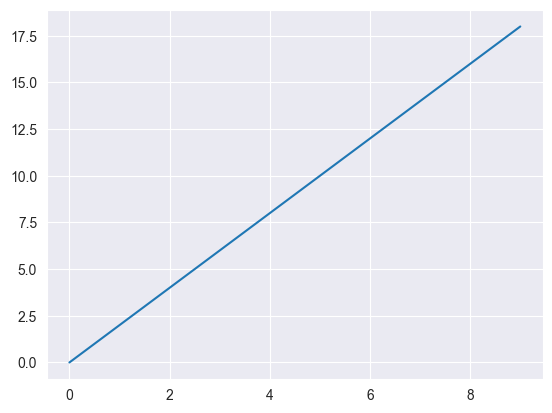

In [2]:
# code 2-1 맷플롯립 블러오기
import matplotlib.pyplot as plt

# code 2-2 선형적 관계를 보여 주는 그래프 그리기
x = range(0, 10)
y =[2 * value for value in x]
plt.plot(x, y)
plt.show()

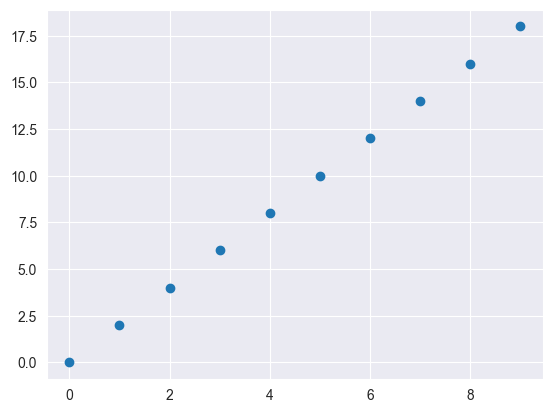

In [2]:
# code 2-3 개별 데이터 포인트를 표시하는 그래프 그리기
plt.scatter(x, y)
plt.show()

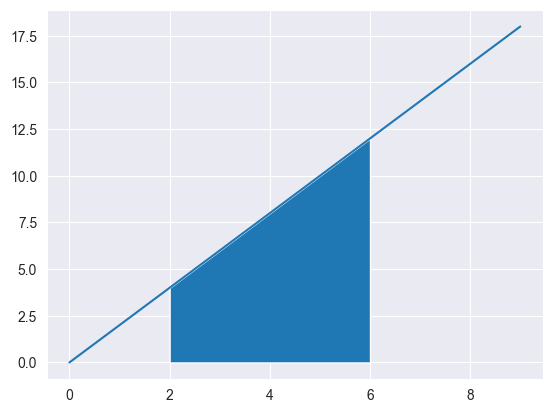

In [4]:
# code 2-4 선 그래프 아래 특정 구간을 음영 처리하기
# code 1-28 활용하기
def is_in_interval(number, minimum, maximum):
    return minimum <= number <= maximum

plt.plot(x, y)
where = [is_in_interval(value, 2, 6) for value in x]
plt.fill_between(x, y, where=where)
plt.show()

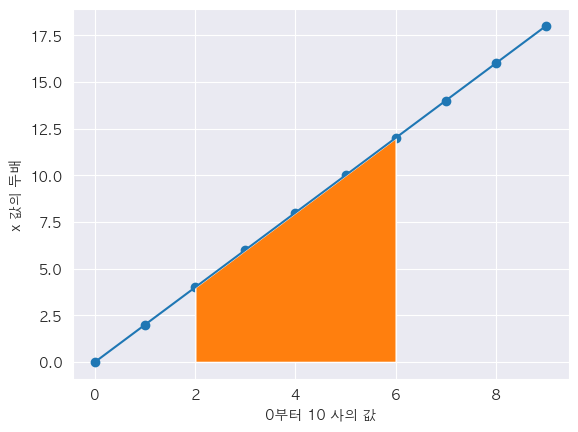

In [7]:
# code 2-5 일직선에 개별 데이터 드러내기
plt.scatter(x, y)
plt.plot(x, y)
plt.fill_between(x, y, where=where)

# code 2-6 축 레이블링하기
plt.xlabel('0부터 10 사의 값')
plt.ylabel('x 값의 두배')
plt.show()


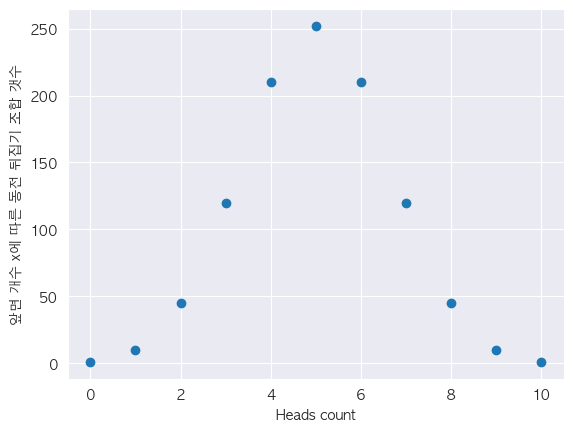

In [12]:
# code 2-7 동전 던지기의 가중 표본 공간 그리기
from collections import defaultdict
from itertools import product

def generate_coin_sample_space(num_flips=10):
  weighted_sample_space = defaultdict(int)
  for coin_flips in product(['앞면', '뒷면'], repeat=num_flips):
    heads_count = len([outcome for outcome in coin_flips
                      if outcome == '앞면'])
    weighted_sample_space[heads_count] += 1
  return weighted_sample_space

weighted_sample_space = generate_coin_sample_space()
assert weighted_sample_space[10] == 1
assert weighted_sample_space[9] == 10

x_10_flips = list(weighted_sample_space.keys())
y_10_flips = [weighted_sample_space[key] for key in x_10_flips]
plt.scatter(x_10_flips, y_10_flips)
plt.xlabel('Heads count')
plt.ylabel('앞면 개수 x에 따른 동전 뒤집기 조합 갯수')
plt.show()

In [9]:
# code 2-8 동전 뒤집기 확률 그래프
sample_space_size = sum(weighted_sample_space.values())
prob_x_10_flips = [value / sample_space_size for value in y_10_flips]
plt.scatter(x_10_flips, prob_x_10_flips)
plt.xlabel('Heads count')
plt.ylabel('prob')
plt.show()

NameError: name 'weighted_sample_space' is not defined

In [14]:
# code 2-9 모든 확율을 더하면 1.0이 된다는 검증하기
assert sum(prob_x_10_flips) == 1

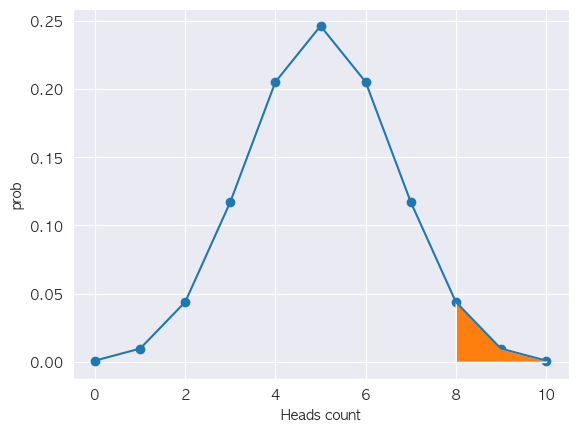

In [15]:
# code 2-10 확률 곡선 아래의 특정 구간 음영 처리하기
plt.plot(x_10_flips, prob_x_10_flips)
plt.scatter(x_10_flips, prob_x_10_flips)
where = [is_in_interval(value, 8, 10) for value in x_10_flips]
plt.fill_between(x_10_flips, prob_x_10_flips, where=where)
plt.xlabel('Heads count')
plt.ylabel('prob')
plt.show()

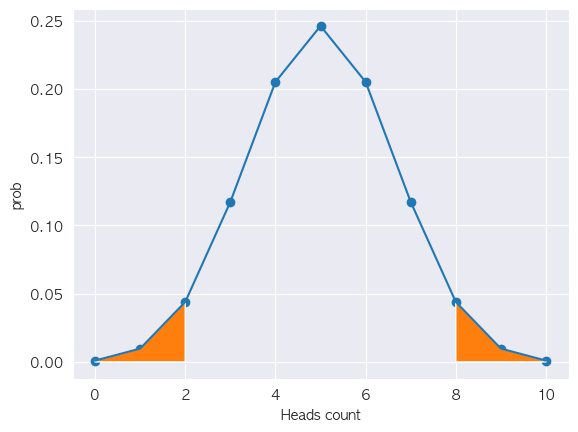

In [16]:
# code 2-11 확률 곡선의 극단적인 구간 음영 처리하기
plt.plot(x_10_flips, prob_x_10_flips)
plt.scatter(x_10_flips, prob_x_10_flips)
where =[not is_in_interval(value,3,7) for value in x_10_flips]
plt.fill_between(x_10_flips, prob_x_10_flips, where=where)
plt.xlabel('Heads count')
plt.ylabel('prob')
plt.show()

In [18]:
# code 2-12 동전 뒤집기 분포 20번에 대한 확률 계산하기
# code 1-33 동전 뒤집기 20번에서 앞면이 극단적으로 많이 나타내는 경우 분석하기
weighted_sample_space_20_flips = generate_coin_sample_space(num_flips=20)
x_20_flips = list(weighted_sample_space_20_flips.keys())
y_20_flips = [weighted_sample_space_20_flips[key] for key in x_20_flips]
sample_space_size = sum(weighted_sample_space_20_flips.values())
prob_x_20_flips = [value / sample_space_size for value in y_20_flips]

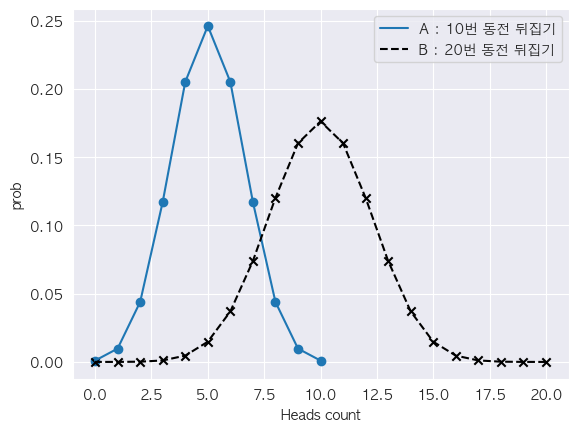

In [19]:
# code 2-13 동시에 두 분포도 그리기
plt.plot(x_10_flips, prob_x_10_flips, label = 'A : 10번 동전 뒤집기')
plt.scatter(x_10_flips, prob_x_10_flips)
plt.plot(x_20_flips, prob_x_20_flips, color = 'black', linestyle = '--',
         label = 'B : 20번 동전 뒤집기')
plt.scatter(x_20_flips, prob_x_20_flips, color ='k', marker='x')
plt.xlabel('Heads count')
plt.ylabel('prob')
plt.legend()
plt.show()